# Практическая работа № 4 — последовательное понижение степени полинома

**Исходные данные:** первые 60 наблюдений количества SSH brute-force инцидентов (шаг — 30 секунд, с 03.09.2026 10:26:30).  
**Методы:** канонический полином (система Вандермонда), полином Лагранжа, полином Ньютона, схема Эйткена.

## Важная математическая оговорка

- **60 различных узлов однозначно задают полином степени не выше 59**. Полином степени 60 по 60 узлам **не единственен**: можно прибавлять к полиному степени 59 произведение `C · ∏(t−tᵢ)` с произвольным `C`. Поэтому степень 60 в результатах помечается как неидентифицируемая, и честный перебор **начинается с 59**.
- В **точной интерполяции** полином степени `d` строится по `d+1` узлам. Мы **не подменяем** это регрессией по всем точкам. Степень уменьшается последовательно: `59, 58, ..., 1, 0`.
- Если оценивать ошибку на самих узлах, степень 59 даст ноль по определению. Для **поиска полезной степени** выделяем фиксированные скрытые наблюдения и считаем ошибки **по ним**. Они не участвуют в построении моделей степени `≤ 47`.
- Четыре метода при одинаковых узлах задают **один и тот же полином** и в точной арифметике имеют одинаковую точность. Их графики могут различаться только из-за численной погрешности.
- Для соответствия заданию также выполняем полный перебор степеней `29..0` на двух временных интервалах **1–30** и **31–60**. В отчёте можно выбрать три представительные степени в каждом интервале.

Ноутбук показывает *каждый шаг снижения степени*, графики, коэффициенты, сравнительные таблицы и автоматически находит лучшую степень по MAE на скрытых точках. Подходящий порог MAPE пользователь может поменять.

In [1]:
import importlib.util, subprocess, sys
for p in ('mpmath', 'numpy', 'pandas', 'matplotlib'):
    if importlib.util.find_spec(p) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', p])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mpmath as mp
from IPython.display import display
try:
    from ipywidgets import interact, IntSlider, Dropdown, Checkbox
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    print('ipywidgets не установлен: интерактивный просмотр заменён вызовом функции interactive_plot(...)')

mp.mp.dps = 90  # высокая точность важна для степени 59
pd.set_option('display.max_columns', 20)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
print('Среда готова; точность mpmath:', mp.mp.dps, 'знаков')

ipywidgets не установлен: интерактивный просмотр заменён вызовом функции interactive_plot(...)
Среда готова; точность mpmath: 90 знаков


60 точек; среднее 21.833, диапазон [16; 27]


,Наблюдение,Инцидентов / 30 с
0,1,21
1,2,18
2,3,21
3,4,18
4,5,18
5,6,22
6,7,16
7,8,27
8,9,26
9,10,22


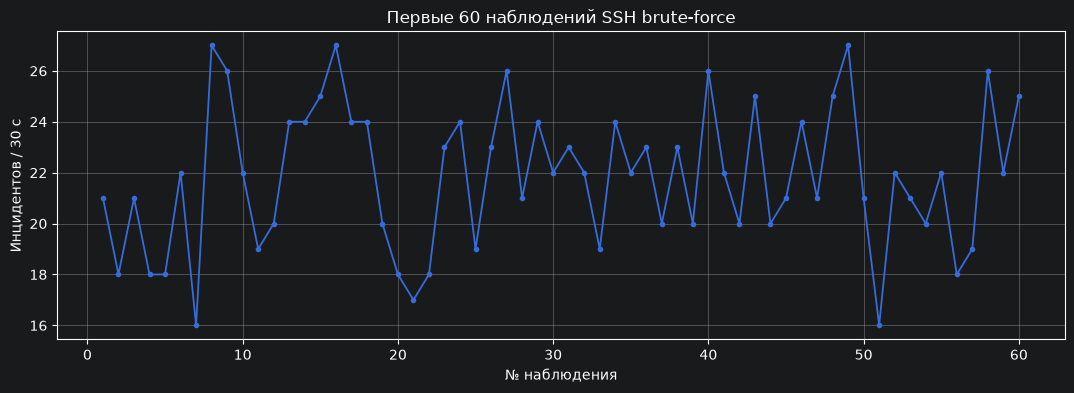

In [2]:
# Первые 60 реальных значений из таблицы «Ермакова 1».
Y = np.array([
    21,18,21,18,18,22,16,27,26,22,19,20,24,24,25,
    27,24,24,20,18,17,18,23,24,19,23,26,21,24,22,
    23,22,19,24,22,23,20,23,20,26,22,20,25,20,21,
    24,21,25,27,21,16,22,21,20,22,18,19,26,22,25
], dtype=float)
T = np.arange(1, len(Y) + 1, dtype=int)
assert len(Y) == 60
print(f'60 точек; среднее {np.mean(Y):.3f}, диапазон [{np.min(Y):.0f}; {np.max(Y):.0f}]')
display(pd.DataFrame({'Наблюдение':T, 'Инцидентов / 30 с':Y.astype(int)}).head(12))
plt.figure(figsize=(13,4))
plt.plot(T, Y, marker='o', markersize=3, linewidth=1.3)
plt.title('Первые 60 наблюдений SSH brute-force');plt.xlabel('№ наблюдения');plt.ylabel('Инцидентов / 30 с');plt.show()

## 1. Реализация четырёх **разных форм вычисления** интерполяционного полинома

Здесь `u = (t − центр) / масштаб` — линейная нормировка времени. Она уменьшает численные ошибки, не меняя степени и значения полинома.

- **Канонический:** `P(u) = a₀ + a₁u + ⋯ + aₙuⁿ`; коэффициенты из СЛАУ Вандермонда.
- **Лагранж:** базисные полиномы; для устойчивого вычисления применяется эквивалентная барицентрическая форма.
- **Ньютон:** форма с разделёнными разностями.
- **Эйткен:** рекуррентная интерполяционная схема Невилла–Эйткена.

При степени 0 полином является константой. Все четыре алгоритма поддерживают и этот случай.

In [3]:
METHODS = ('Канонический', 'Лагранж', 'Ньютон', 'Эйткен')

def choose_nodes(tpool, ypool, degree):
    """Ровно d+1 равномерно расположенных ВЫБРАННЫХ узлов для интерполяции."""
    if not 0 <= degree < len(tpool):
        raise ValueError('Для степени d требуется d+1 различных узлов')
    if degree == 0:
        ix = np.array([len(tpool)//2], dtype=int)
    else:
        ix = np.rint(np.linspace(0, len(tpool)-1, degree+1)).astype(int)
    assert len(np.unique(ix)) == degree+1
    return np.asarray(tpool)[ix], np.asarray(ypool)[ix]

def build_poly(xnodes, ynodes):
    """Один и тот же полином как 4 вычислительные формы."""
    xx = [mp.mpf(int(x)) for x in xnodes]
    yy = [mp.mpf(str(float(y))) for y in ynodes]
    n = len(xx)
    center = (xx[0]+xx[-1])/2
    scale = (xx[-1]-xx[0])/2 if n > 1 else mp.mpf(1)
    uu = [(x-center)/scale for x in xx]
    # Каноническая форма: V * a = y
    if n == 1:
        canonical = [yy[0]]
        ww = [mp.mpf(1)]
        divided = [yy[0]]
    else:
        V = mp.matrix([[u**j for j in range(n)] for u in uu])
        canonical = list(mp.lu_solve(V, mp.matrix(yy)))
        # Весовые коэффициенты Лагранжа
        ww = [1/mp.fprod(uu[i]-uu[j] for j in range(n) if j!=i) for i in range(n)]
        # Разделённые разности Ньютона
        dd = yy[:]
        divided = [dd[0]]
        for k in range(1, n):
            dd = [(dd[j+1]-dd[j])/(uu[j+k]-uu[j]) for j in range(n-k)]
            divided.append(dd[0])
    return {'x': xx, 'y': yy, 'u': uu, 'center': center, 'scale': scale,
            'canonical': canonical, 'weights': ww, 'newton': divided, 'degree': n-1}

def evaluate_one(p, t, method):
    u = (mp.mpf(str(float(t))) - p['center']) / p['scale']
    nodes, yy = p['u'], p['y']
    n = len(nodes)
    for j in range(n):
        if u == nodes[j]: return yy[j]
    if method == 'Канонический':
        v = mp.mpf(0)
        for a in reversed(p['canonical']): v = v*u+a
        return v
    if method == 'Лагранж':
        z = [p['weights'][j] / (u-nodes[j]) for j in range(n)]
        return mp.fsum(z[j]*yy[j] for j in range(n)) / mp.fsum(z)
    if method == 'Ньютон':
        v = p['newton'][-1]
        for j in range(n-2, -1, -1): v = v*(u-nodes[j])+p['newton'][j]
        return v
    if method == 'Эйткен':
        q = yy[:]
        for width in range(1,n):
            for i in range(n-width):
                j=i+width
                q[i] = ((u-nodes[i])*q[i+1] - (u-nodes[j])*q[i])/(nodes[j]-nodes[i])
        return q[0]
    raise ValueError(f'Неизвестный метод: {method}')

def evaluate(p, time_points, method):
    return np.array([float(evaluate_one(p, t, method)) for t in np.asarray(time_points)])

def calc_metrics(actual, forecast):
    a, f = np.asarray(actual,float), np.asarray(forecast,float)
    diff = a-f
    return dict(MAE=float(np.mean(abs(diff))), MSE=float(np.mean(diff**2)),
                RMSE=float(np.sqrt(np.mean(diff**2))), MAPE=float(np.mean(abs(diff)/np.maximum(abs(a),1e-12))*100))

def coeff_table(p):
    return pd.DataFrame({'Степень u': np.arange(p['degree']+1),
          'Канонический a_k': [mp.nstr(z, 13) for z in p['canonical']],
          'Ньютон: разделённая разность c_k': [mp.nstr(z, 13) for z in p['newton']]})

print('Проверка на двух узлах:')
pcheck=build_poly([1,5],[21,18])
print({m:mp.nstr(evaluate_one(pcheck,3.5,m),10) for m in METHODS})

Проверка на двух узлах:
{'Канонический': '19.125', 'Лагранж': '19.125', 'Ньютон': '19.125', 'Эйткен': '19.125'}


## 2. Полный перебор **каждой степени по порядку**

В таблице **60 → 0** степень 60 отображается как невозможная для однозначной интерполяции. Для остальных степеней перебор идёт **без пропусков**.

Для каждого интервала заранее резервируется около 20% точек для проверки (**одни и те же** для всех сравниваемых степеней). Поэтому:

- Степени `0..(число обучающих точек − 1)` оцениваются по независимым скрытым точкам.
- Более высокие степени можно построить только с использованием части/всех скрытых точек. Для них показывается **ошибка на наблюдениях**, но они **не участвуют** в выборе лучшего проверенного полинома.

**Критерий «максимально близко к нашим данным» = минимальная MAE на скрытых наблюдениях.** Также показывается первая степень при движении сверху вниз, достигшая заданного порога MAPE (по умолчанию 15%).

Это именно **интерполяция** по `d+1` выбранным узлам. Не путать с полиномиальной регрессией МНК по всем 60 наблюдениям.

In [4]:
INTERVALS = {'Все 60 (1–60)': (T, Y), 'Первый (1–30)': (T[:30],Y[:30]), 'Второй (31–60)': (T[30:],Y[30:])}
MAPE_TARGET = 15.0  # Пользовательский критерий, НЕ требование методички
SCAN = {}             # отдельные результаты для каждого интервала
MODELS = {}           # ключ (интервал, степень): полином и используемые узлы

for interval_name, (tx, yy) in INTERVALS.items():
    n = len(tx)
    test_mask = np.zeros(n, dtype=bool)
    test_mask[np.arange(3,n,5)] = True  # фиксированные скрытые 4,9,...; крайние точки остаются
    train_x, train_y = tx[~test_mask], yy[~test_mask]
    test_x, test_y = tx[test_mask], yy[test_mask]
    max_valid_degree = len(train_x)-1
    table = []

    for d in range(n-1, -1, -1):  # 59,58,...,0 либо 29,..,0
        # Для d>max_valid_degree использовать только обучающие узлы невозможно.
        # Такие полиномы показаны как демонстрация переобучения и интерполяции.
        xpool, ypool = (train_x, train_y) if d<=max_valid_degree else (tx, yy)
        nodes_x, nodes_y = choose_nodes(xpool, ypool, d)
        p = build_poly(nodes_x, nodes_y)
        MODELS[(interval_name,d)] = (p, np.array(nodes_x,dtype=int), np.array(nodes_y,float))

        for method in METHODS:
            y_all = evaluate(p, tx, method)
            all_metrics = calc_metrics(yy, y_all)
            if d<=max_valid_degree:
                val_metrics = calc_metrics(test_y, evaluate(p,test_x,method))
            else:
                val_metrics = dict(MAE=np.nan, MSE=np.nan, RMSE=np.nan, MAPE=np.nan)
            table.append({'Интервал':interval_name,'Метод':method,'Степень':d,
                'Узлов':d+1, 'Проверка независимая':d<=max_valid_degree,
                'MAE проверка':val_metrics['MAE'], 'RMSE проверка':val_metrics['RMSE'],
                'MAPE проверка, %':val_metrics['MAPE'],
                'MAE все точки':all_metrics['MAE'], 'RMSE все точки':all_metrics['RMSE']})
    df = pd.DataFrame(table)
    SCAN[interval_name] = {'table':df, 'train_x':train_x, 'test_x':test_x,
                            'train_y':train_y, 'test_y':test_y, 'max_degree':n-1,
                            'max_valid_degree':max_valid_degree}
    print(f'ГОТОВО: {interval_name} — {n} степеней × 4 метода = {len(df)} записей; '
          f'{len(test_x)} проверочных точек; проверенные степени 0..{max_valid_degree}')

print('\nПояснение для степени 60 при 60 наблюдениях: степень 60 не даёт единственного интерполяционного полинома.')

ГОТОВО: Все 60 (1–60) — 60 степеней × 4 метода = 240 записей; 12 проверочных точек; проверенные степени 0..47
ГОТОВО: Первый (1–30) — 30 степеней × 4 метода = 120 записей; 6 проверочных точек; проверенные степени 0..23
ГОТОВО: Второй (31–60) — 30 степеней × 4 метода = 120 записей; 6 проверочных точек; проверенные степени 0..23

Пояснение для степени 60 при 60 наблюдениях: степень 60 не даёт единственного интерполяционного полинома.


## 3. Сводные таблицы ошибок по степеням

Для каждого интервала выводится **одна компактная таблица**: строки — полный перечень степеней сверху вниз, столбцы — четыре метода (MAE на скрытых точках). Полином при заданных узлах один, поэтому столбцы методов совпадают с точностью до вычислительной погрешности. `NaN` означает, что полином использовал скрытые точки и независимая оценка для него **не выполнялась**.

In [5]:
for name, item in SCAN.items():
    print('\n' + '='*80 + '\n' + name)
    t = item['table']
    one = t[t['Метод'] == METHODS[0]].set_index('Степень')[['Узлов', 'Проверка независимая']]
    for m in METHODS:  # четыре метода — четыре столбца MAE одного и того же полинома
        one[f'MAE {m}'] = t[t['Метод'] == m].set_index('Степень')['MAE проверка']
    one['RMSE (любой метод)'] = t[t['Метод'] == METHODS[0]].set_index('Степень')['RMSE проверка']
    one['MAPE, % (любой метод)'] = t[t['Метод'] == METHODS[0]].set_index('Степень')['MAPE проверка, %']
    one = one.sort_index(ascending=False).reset_index()
    print(f'Все степени {item["max_degree"]}→0 в одной таблице; NaN — независимая проверка не выполнялась.')
    with pd.option_context('display.max_rows', 70):
        display(one.round(4))


Все 60 (1–60)
Все степени 59→0 в одной таблице; NaN — независимая проверка не выполнялась.


,Степень,Узлов,Проверка независимая,MAE Канонический,MAE Лагранж,MAE Ньютон,MAE Эйткен,RMSE (любой метод),"MAPE, % (любой метод)"
0,59,60,False,NaN,NaN,NaN,NaN,NaN,NaN
1,58,59,False,NaN,NaN,NaN,NaN,NaN,NaN
2,57,58,False,NaN,NaN,NaN,NaN,NaN,NaN
3,56,57,False,NaN,NaN,NaN,NaN,NaN,NaN
4,55,56,False,NaN,NaN,NaN,NaN,NaN,NaN
5,54,55,False,NaN,NaN,NaN,NaN,NaN,NaN
6,53,54,False,NaN,NaN,NaN,NaN,NaN,NaN
7,52,53,False,NaN,NaN,NaN,NaN,NaN,NaN
8,51,52,False,NaN,NaN,NaN,NaN,NaN,NaN
9,50,51,False,NaN,NaN,NaN,NaN,NaN,NaN



Первый (1–30)
Все степени 29→0 в одной таблице; NaN — независимая проверка не выполнялась.


,Степень,Узлов,Проверка независимая,MAE Канонический,MAE Лагранж,MAE Ньютон,MAE Эйткен,RMSE (любой метод),"MAPE, % (любой метод)"
0,29,30,False,NaN,NaN,NaN,NaN,NaN,NaN
1,28,29,False,NaN,NaN,NaN,NaN,NaN,NaN
2,27,28,False,NaN,NaN,NaN,NaN,NaN,NaN
3,26,27,False,NaN,NaN,NaN,NaN,NaN,NaN
4,25,26,False,NaN,NaN,NaN,NaN,NaN,NaN
5,24,25,False,NaN,NaN,NaN,NaN,NaN,NaN
6,23,24,True,18241.1446,18241.1446,18241.1446,18241.1446,44214.3265,76255.9142
7,22,23,True,1397.2944,1397.2944,1397.2944,1397.2944,3385.5329,5839.1227
8,21,22,True,5215.8603,5215.8603,5215.8603,5215.8603,12521.7694,21853.4368
9,20,21,True,1266.5543,1266.5543,1266.5543,1266.5543,3050.5550,5295.9024



Второй (31–60)
Все степени 29→0 в одной таблице; NaN — независимая проверка не выполнялась.


,Степень,Узлов,Проверка независимая,MAE Канонический,MAE Лагранж,MAE Ньютон,MAE Эйткен,RMSE (любой метод),"MAPE, % (любой метод)"
0,29,30,False,NaN,NaN,NaN,NaN,NaN,NaN
1,28,29,False,NaN,NaN,NaN,NaN,NaN,NaN
2,27,28,False,NaN,NaN,NaN,NaN,NaN,NaN
3,26,27,False,NaN,NaN,NaN,NaN,NaN,NaN
4,25,26,False,NaN,NaN,NaN,NaN,NaN,NaN
5,24,25,False,NaN,NaN,NaN,NaN,NaN,NaN
6,23,24,True,25911.9620,25911.9620,25911.9620,25911.9620,62747.5473,117678.8037
7,22,23,True,1431.3923,1431.3923,1431.3923,1431.3923,3466.6512,6504.4163
8,21,22,True,9785.7228,9785.7228,9785.7228,9785.7228,23440.3315,44420.9297
9,20,21,True,325.5737,325.5737,325.5737,325.5737,765.9054,1481.6818


## 4. Поиск оптимального полинома и первого достигнутого порога

**«Оптимальный»** — минимальная MAE на фиксированных скрытых точках, а **«первая приемлемая степень»** — первая сверху вниз, у которой MAPE не превышает `MAPE_TARGET`.

Если такой степени нет, выводится соответствующее сообщение. Все выводы основаны на реальных значениях SSH-инцидентов, а не на демонстрационных числах.

In [6]:
BEST = {}
rows=[]
for name, item in SCAN.items():
    for method in METHODS:
        z = item['table']
        valid = z[(z['Метод']==method) & (z['Проверка независимая'])].copy()
        best = valid.sort_values(['MAE проверка', 'Степень']).iloc[0]
        reached = valid.sort_values('Степень',ascending=False)
        reached = reached[reached['MAPE проверка, %'] <= MAPE_TARGET]
        first = int(reached.iloc[0]['Степень']) if not reached.empty else None
        BEST[(name,method)] = int(best['Степень'])
        rows.append({'Интервал':name,'Метод':method,
                     'Лучшая степень (MAE)':int(best['Степень']),
                     'MAE':best['MAE проверка'], 'MAPE, %':best['MAPE проверка, %'],
                     'Первая степень с MAPE ≤ порога': first if first is not None else 'не найдена'})
summary = pd.DataFrame(rows)
display(summary.round(4))
print(f'Порог приемлемости: MAPE ≤ {MAPE_TARGET}% (можно менять в коде).')
print('При одинаковых выбранных узлах оптимальные степени у четырёх методов должны совпадать,')
print('если численная погрешность вычисления достаточно мала.')

,Интервал,Метод,Лучшая степень (MAE),MAE,"MAPE, %",Первая степень с MAPE ≤ порога
0,Все 60 (1–60),Канонический,8,2.2796,10.0146,8
1,Все 60 (1–60),Лагранж,8,2.2796,10.0146,8
2,Все 60 (1–60),Ньютон,8,2.2796,10.0146,8
3,Все 60 (1–60),Эйткен,8,2.2796,10.0146,8
4,Первый (1–30),Канонический,1,2.7069,11.9699,2
5,Первый (1–30),Лагранж,1,2.7069,11.9699,2
6,Первый (1–30),Ньютон,1,2.7069,11.9699,2
7,Первый (1–30),Эйткен,1,2.7069,11.9699,2
8,Второй (31–60),Канонический,5,1.4513,6.5496,8
9,Второй (31–60),Лагранж,5,1.4513,6.5496,8


Порог приемлемости: MAPE ≤ 15.0% (можно менять в коде).
При одинаковых выбранных узлах оптимальные степени у четырёх методов должны совпадать,
если численная погрешность вычисления достаточно мала.


## 5. Графики изменения ошибки при снижении степени

Для всех **четырёх** методов и каждого интервала построена линия проверочной ошибки по степеням. На графике отмечена лучшая степень.

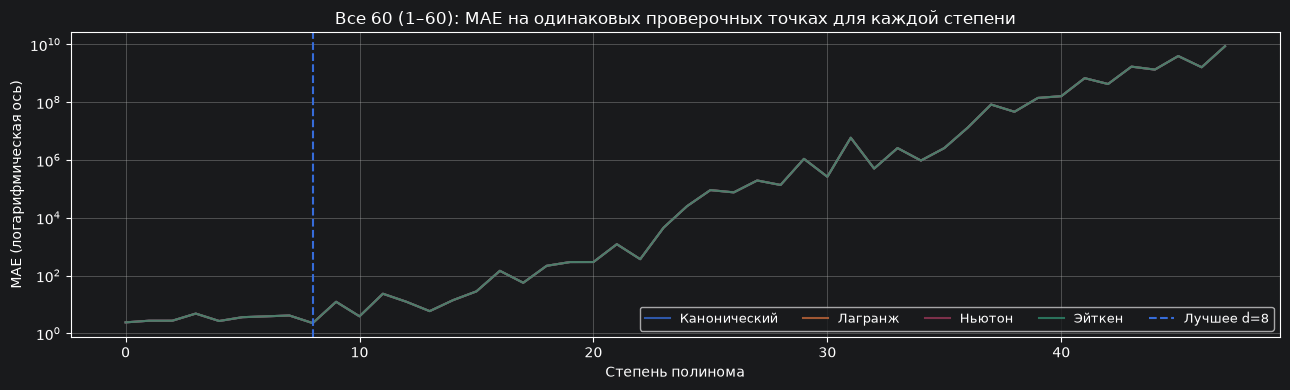

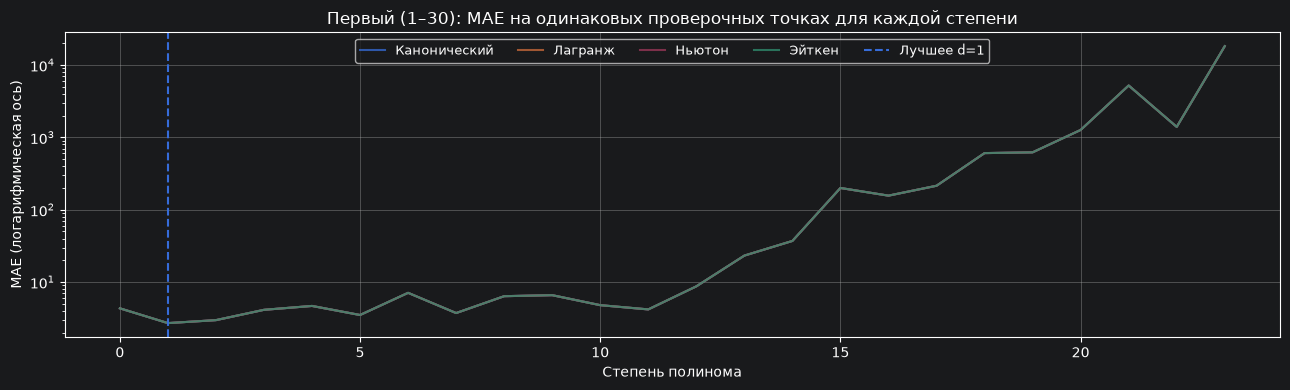

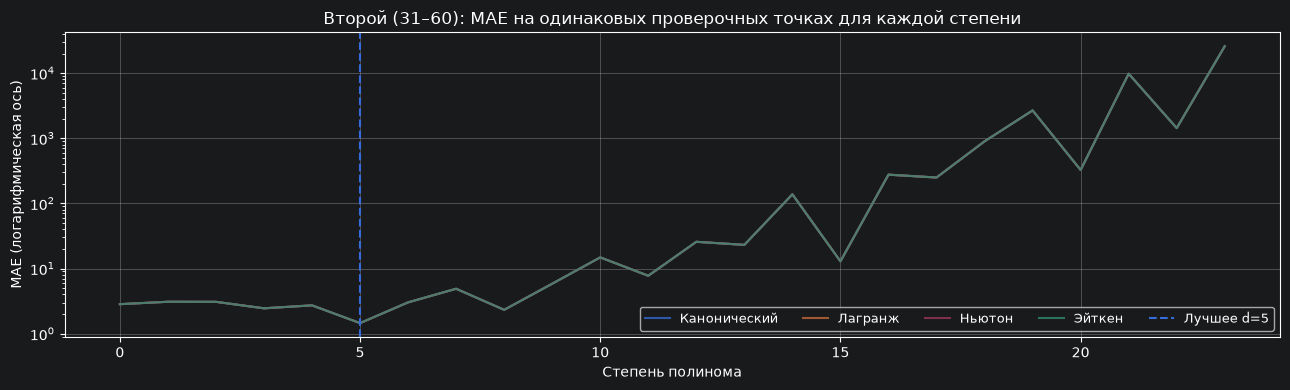

In [7]:
for name, item in SCAN.items():
    fig, ax = plt.subplots(figsize=(13,4))
    for method in METHODS:
        part=item['table']
        s=part[(part['Метод']==method)&(part['Проверка независимая'])].sort_values('Степень')
        ax.plot(s['Степень'], np.maximum(s['MAE проверка'], 1e-12), alpha=.75, label=method)
    b=BEST[(name,'Канонический')]
    ax.axvline(b,ls='--',linewidth=1.5,label=f'Лучшее d={b}')
    ax.set_title(f'{name}: MAE на одинаковых проверочных точках для каждой степени')
    ax.set_xlabel('Степень полинома'); ax.set_ylabel('MAE (логарифмическая ось)')
    ax.set_yscale('log');ax.legend(ncol=5,fontsize=9)
    plt.tight_layout(); plt.show()

## 6. Графики **четырёх методов** при лучшей степени

Точки красного цвета — независимые проверочные наблюдения; чёрные точки — узлы полинома. Видно, насколько близко проходила бы восстановленная кривая к скрытым данным.

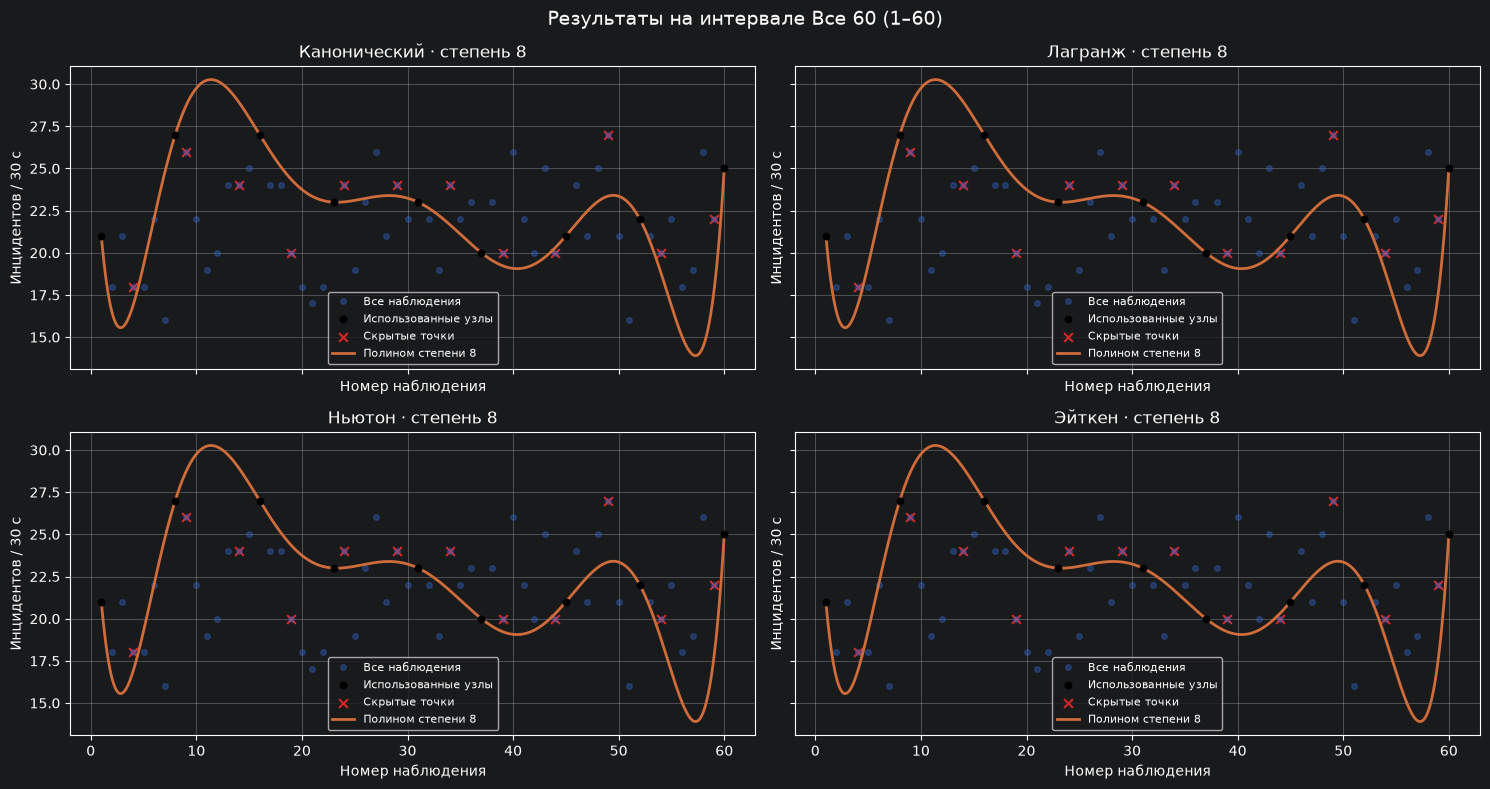

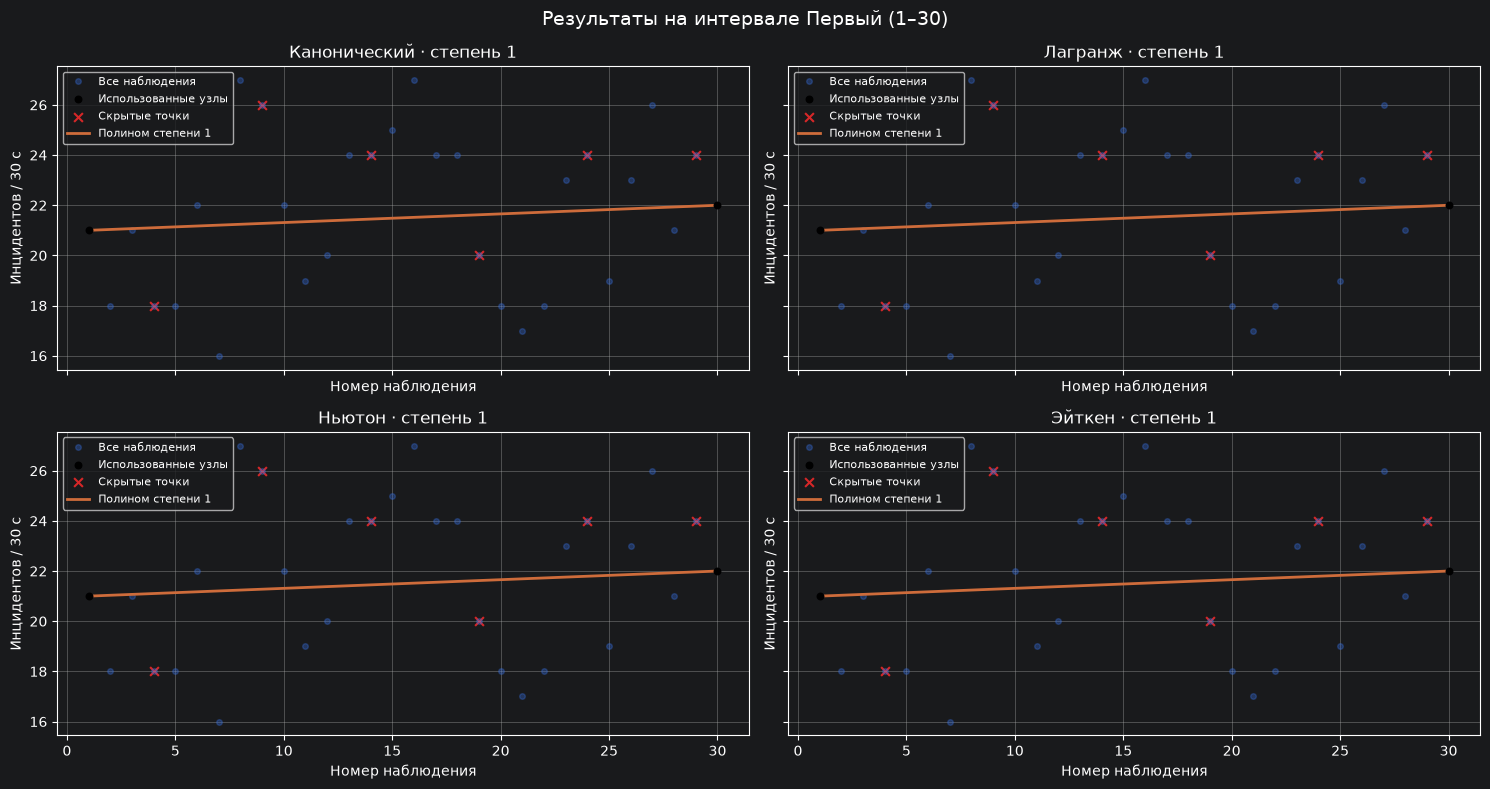

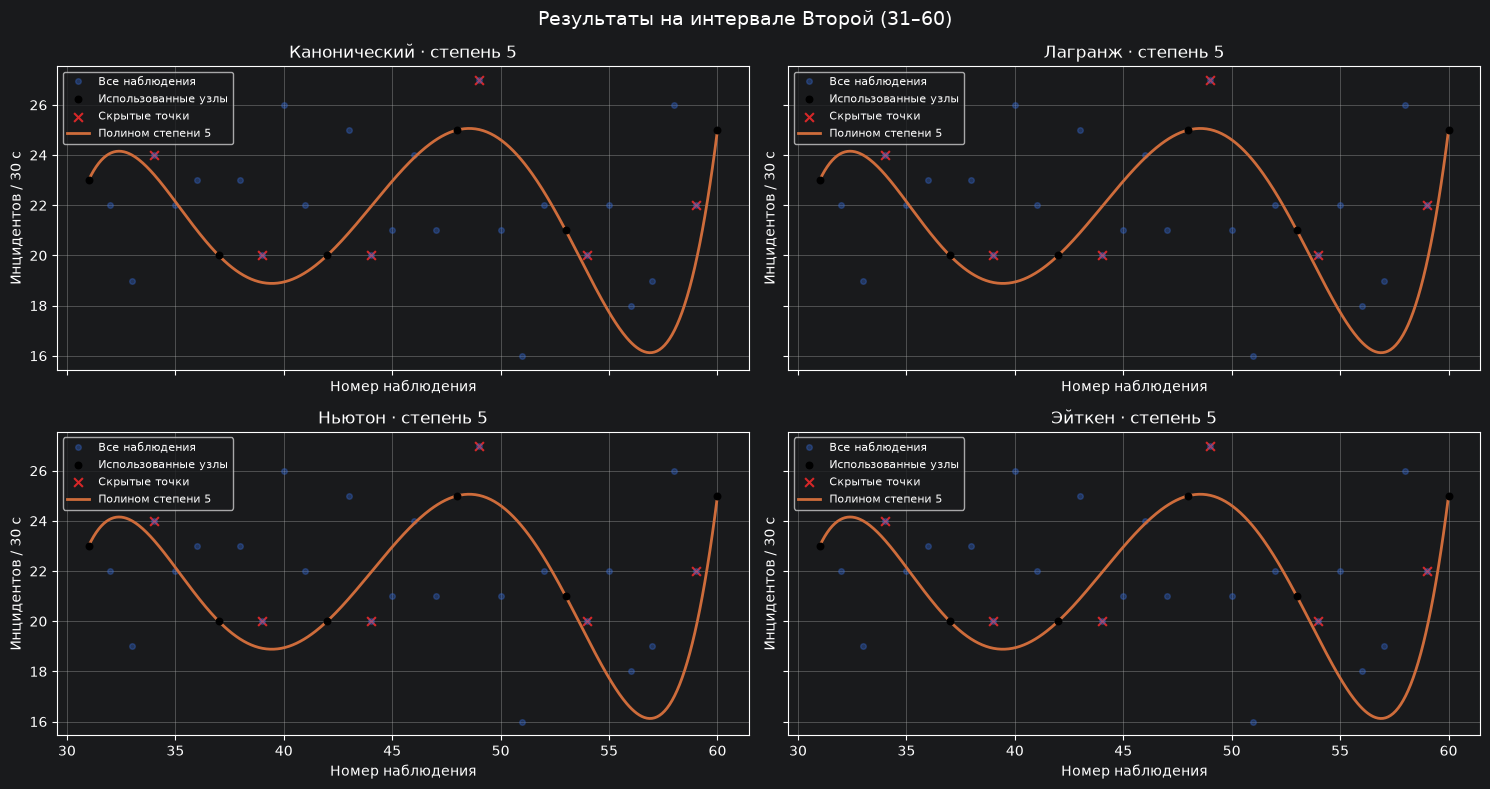

In [8]:
for name, (tx, yy) in INTERVALS.items():
    fig, axes=plt.subplots(2,2,figsize=(15,8),sharex=True,sharey=True)
    for ax,method in zip(axes.flat,METHODS):
        degree=BEST[(name,method)]
        p,nx,ny=MODELS[(name,degree)]
        dense=np.linspace(tx[0],tx[-1],500)
        hat=evaluate(p,dense,method)
        ax.plot(tx,yy,'o',alpha=.35,ms=4,label='Все наблюдения')
        ax.scatter(nx,ny,s=22,color='black',label='Использованные узлы',zorder=4)
        ax.scatter(SCAN[name]['test_x'],SCAN[name]['test_y'],marker='x',s=40,color='tab:red',label='Скрытые точки')
        ax.plot(dense,hat,lw=2,label=f'Полином степени {degree}')
        ax.set_title(method + f' · степень {degree}')
        ax.set_xlabel('Номер наблюдения');ax.set_ylabel('Инцидентов / 30 с')
        ax.legend(fontsize=8)
    fig.suptitle(f'Результаты на интервале {name}',fontsize=14)
    plt.tight_layout();plt.show()

## 7. Просмотр **любой** степени и метода через ползунок

Выберите интервал, метод и степень. Это позволяет в Colab просмотреть **каждый полином, вплоть до степени 59**, не перегружая документ сотнями графиков. Можно переключать обычную шкалу (огромные всплески будут видны) и ограниченную вертикальную шкалу (видны исходные узлы). Ограничение оси — только способ показа, ошибка всегда считается **без обрезки**.

Для Google Colab управление виджетами автоматически включается, если поддерживается средой.

Вы можете вызвать interactive_plot(interval="Все 60 (1–60)", method="Ньютон", degree=10)


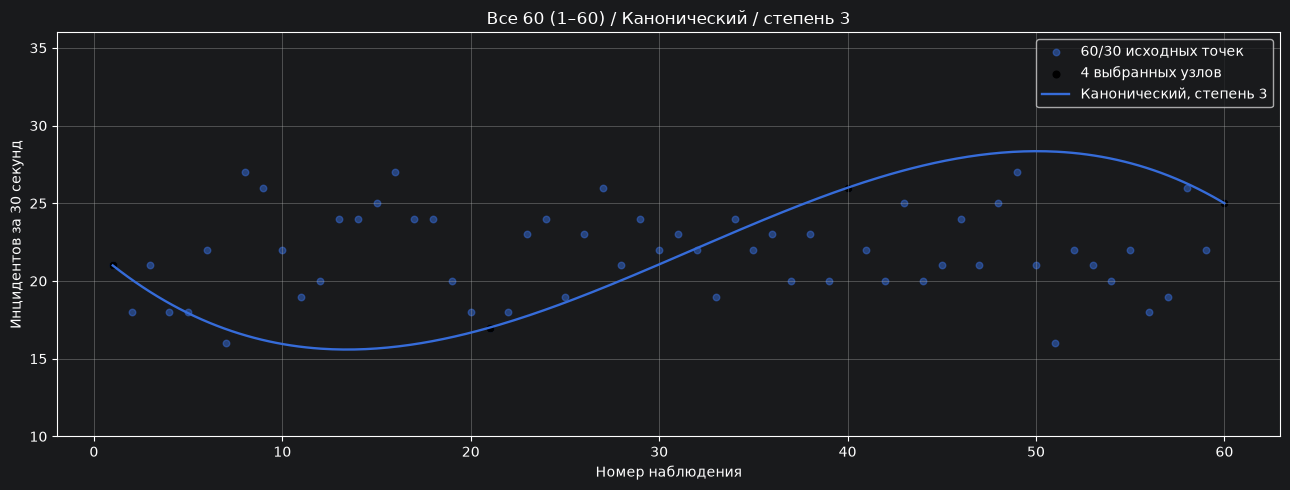

MAE на скрытых точках: 4.8659; MAPE: 21.84%


In [9]:
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

def interactive_plot(interval='Все 60 (1–60)', method='Канонический', degree=3, show_full_scale=False):
    tx,yy=INTERVALS[interval]
    degree=min(degree, len(tx)-1)
    p,nx,ny=MODELS[(interval,degree)]
    dense=np.linspace(tx[0],tx[-1],300)
    hat=evaluate(p,dense,method)
    fig,ax=plt.subplots(figsize=(13,5))
    ax.scatter(tx,yy,s=22,label='60/30 исходных точек',alpha=.5)
    ax.scatter(nx,ny,s=23,color='black',label=f'{degree+1} выбранных узлов')
    ax.plot(dense,hat,lw=1.7,label=f'{method}, степень {degree}')
    if not show_full_scale:
        ax.set_ylim(10,36)
        if np.max(abs(hat))>100:
            print('ВНИМАНИЕ: по вертикали отображается только [10;36]. Полином выходит за границы; ошибки без ограничений.')
    else:
        ax.set_yscale('symlog',linthresh=30)
    ax.set_title(f'{interval} / {method} / степень {degree}')
    ax.set_xlabel('Номер наблюдения');ax.set_ylabel('Инцидентов за 30 секунд')
    ax.legend();plt.tight_layout();plt.show()
    s=SCAN[interval]['table']
    v=s[(s['Метод']==method)&(s['Степень']==degree)].iloc[0]
    if v['Проверка независимая']:
        print(f"MAE на скрытых точках: {v['MAE проверка']:.4f}; MAPE: {v['MAPE проверка, %']:.2f}%")
    else:
        print('Независимая проверка недоступна: степень слишком высокая для текущего набора обучающих узлов.')

if HAS_WIDGETS:
    interact(interactive_plot,
         interval=Dropdown(options=list(INTERVALS),value='Все 60 (1–60)',description='Интервал'),
         method=Dropdown(options=METHODS,value='Канонический',description='Метод'),
         degree=IntSlider(value=3,min=0,max=59,step=1,continuous_update=False,description='Степень'),
         show_full_scale=Checkbox(value=False,description='Полная шкала (symlog)'));
else:
    print('Вы можете вызвать interactive_plot(interval="Все 60 (1–60)", method="Ньютон", degree=10)')
    interactive_plot(interval='Все 60 (1–60)', method='Канонический', degree=3)

## 8. Коэффициенты полиномов и вывод функций

Для любой степени и любого интервала доступны канонические коэффициенты `a₀..aₙ` и разделённые разности Ньютона `c₀..cₙ`. Для Лагранжа и Эйткена коэффициенты того же **единственного полинома** в канонической форме совпадают. Выражение корректно задаётся **в нормированной переменной** `u=(t−центр)/масштаб`. Для высокой степени вывод 60 коэффициентов может быть объёмным, поэтому ниже отображается полный набор коэффициентов **выбранной** степени; для степени 59 нужно вызвать `show_coeffs` с `degree=59`.

In [10]:
def show_coeffs(interval='Все 60 (1–60)', degree=None):
    if degree is None: degree=BEST[(interval,'Канонический')]
    p,_,_=MODELS[(interval,degree)]
    print(f'Интервал: {interval}, степень: {degree}')
    print(f"u = (t - {mp.nstr(p['center'],9)}) / {mp.nstr(p['scale'],9)}")
    print(f'КАНОНИЧЕСКАЯ ФУНКЦИЯ: P(u) = Σ a_k * u^k, k=0..{degree}')
    print('НЬЮТОН: P(u) = c0 + c1*(u-u0) + c2*(u-u0)*(u-u1) + ...')
    display(coeff_table(p))
    return p

for name in INTERVALS:
    show_coeffs(name)

# Раскомментируйте для ВСЕХ 60 коэффициентов полинома 59 степени:
# show_coeffs('Все 60 (1–60)', degree=59)

Интервал: Все 60 (1–60), степень: 8
u = (t - 30.5) / 29.5
КАНОНИЧЕСКАЯ ФУНКЦИЯ: P(u) = Σ a_k * u^k, k=0..8
НЬЮТОН: P(u) = c0 + c1*(u-u0) + c2*(u-u0)*(u-u1) + ...


,Степень u,Канонический a_k,Ньютон: разделённая разность c_k
0,0,23.13389965928,21.0
1,1,-7.05745732423,25.28571428571
2,2,-49.89882708689,-49.72857142857
3,3,4.556921716895,22.22716450216
4,4,372.26475109,61.7689680187
5,5,-4.752856605841,-196.7205160232
6,6,-720.7693856377,327.2556760852
7,7,9.253392213176,-409.2671644388
8,8,398.2695619753,398.2695619753


Интервал: Первый (1–30), степень: 1
u = (t - 15.5) / 14.5
КАНОНИЧЕСКАЯ ФУНКЦИЯ: P(u) = Σ a_k * u^k, k=0..1
НЬЮТОН: P(u) = c0 + c1*(u-u0) + c2*(u-u0)*(u-u1) + ...


,Степень u,Канонический a_k,Ньютон: разделённая разность c_k
0,0,21.5,21.0
1,1,0.5,0.5


Интервал: Второй (31–60), степень: 5
u = (t - 45.5) / 14.5
КАНОНИЧЕСКАЯ ФУНКЦИЯ: P(u) = Σ a_k * u^k, k=0..5
НЬЮТОН: P(u) = c0 + c1*(u-u0) + c2*(u-u0)*(u-u1) + ...


,Степень u,Канонический a_k,Ньютон: разделённая разность c_k
0,0,23.44286651252,23.0
1,1,13.50340369137,-7.25
2,2,-17.05040074122,9.556818181818
3,3,-55.8717175098,5.43426916221
4,4,17.6075342287,-31.74261597847
5,5,43.36831381842,43.36831381842


## 9. Дополнительно: истинная интерполяция или аппроксимация?

Полином, проходящий через все 60 узлов, имеет степень **59**. Если требовать меньшую степень, но **по-прежнему учитывать все 60 наблюдений при построении**, это будет **полиномиальная аппроксимация** (например, метод наименьших квадратов), а не интерполяция. В методичке используются *интерполяционные* формулы, поэтому основной эксперимент выше применяет ровно `d+1` узлов.

Ниже — **дополнительное, необязательное** сравнение с аппроксимацией МНК, когда коэффициенты оцениваются по всем обучающим точкам. Подбор степени по скрытым точкам ограничен степенью 0..(число обучающих точек−1), чтобы избежать использования будущих данных. Это сравнение показывает практическое отличие интерполяции и сглаживания шумных SSH-данных.

МНК: Все 60 (1–60), лучшая степень 3, MAE=2.3259, MAPE=10.15%


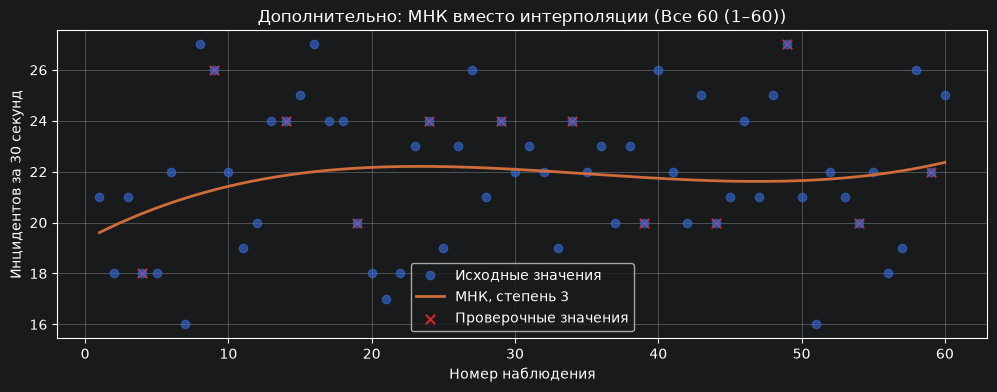

МНК: Первый (1–30), лучшая степень 11, MAE=1.6554, MAPE=7.09%


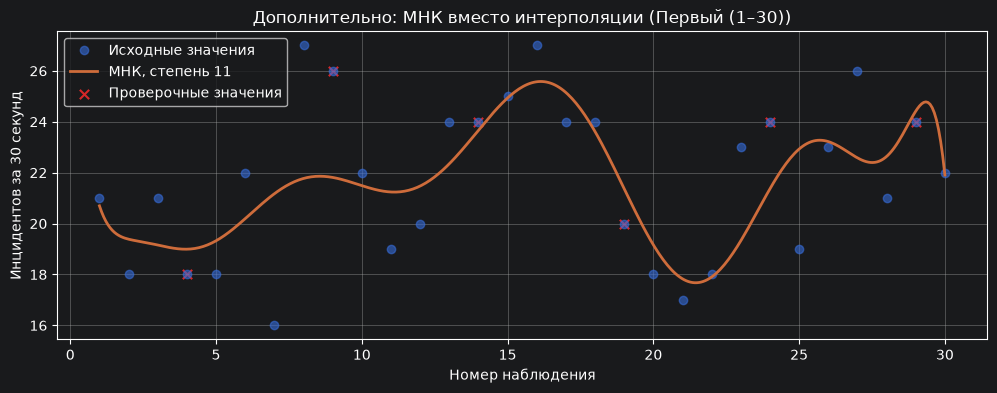

МНК: Второй (31–60), лучшая степень 2, MAE=2.1189, MAPE=9.20%


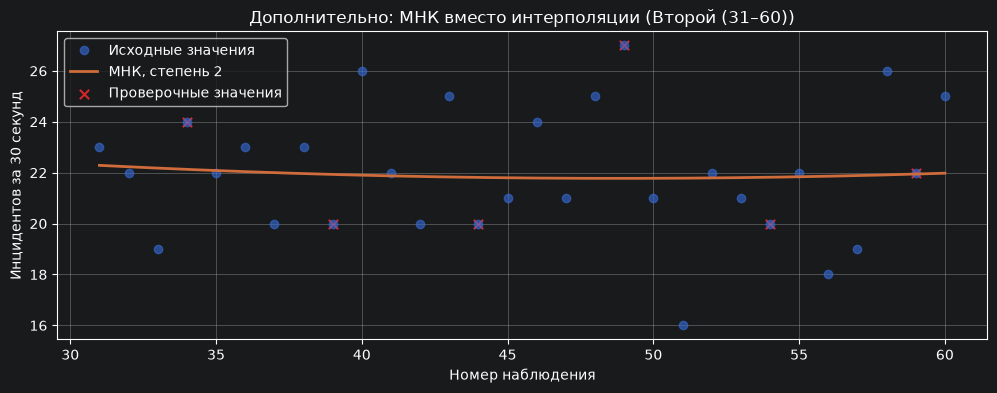

In [11]:
# Численно устойчивый МНК: многочлены Чебышёва, переобозначаемые в стандартный полином.
from numpy.polynomial import Chebyshev
ls_rows=[]; ls_models={}
for name,item in SCAN.items():
    for degree in range(item['max_valid_degree']+1):
        xtr,ytr=item['train_x'],item['train_y']
        xt,yt=item['test_x'],item['test_y']
        mod=Chebyshev.fit(xtr,ytr,deg=degree,domain=[xtr.min(),xtr.max()])
        pred=mod(xt)
        ls_models[(name,degree)]=mod
        ls_rows.append({'Интервал':name,'Степень':degree,**calc_metrics(yt,pred)})
ls_results=pd.DataFrame(ls_rows)
for name in INTERVALS:
    z=ls_results[ls_results['Интервал']==name].sort_values(['MAE','Степень']).iloc[0]
    degree=int(z['Степень'])
    print(f'МНК: {name}, лучшая степень {degree}, MAE={z["MAE"]:.4f}, MAPE={z["MAPE"]:.2f}%')
    x,y=INTERVALS[name]
    dense=np.linspace(x[0],x[-1],400)
    model=ls_models[(name,degree)]
    fig,ax=plt.subplots(figsize=(12,4))
    ax.plot(x,y,'o',alpha=.6,label='Исходные значения')
    ax.plot(dense,model(dense),label=f'МНК, степень {degree}',lw=2)
    ax.scatter(SCAN[name]['test_x'],SCAN[name]['test_y'],color='tab:red',marker='x',label='Проверочные значения',s=45)
    ax.set_title(f'Дополнительно: МНК вместо интерполяции ({name})')
    ax.set_xlabel('Номер наблюдения');ax.set_ylabel('Инцидентов за 30 секунд')
    ax.legend();plt.show()

## 10. Проверка прогноза на реальных будущих наблюдениях 61–90

В исходном файле `total_incidents.csv` всего 100 наблюдений (шаг 30 секунд); по заданию берём первые **90**. Первые 60 уже использованы при построении всех моделей выше (включая выбор степени по скрытым точкам внутри 1–60). Наблюдения **61–90 ни одна модель не видела** — по ним честно проверяем, насколько полиномы, построенные только по точкам 1–60, способны **предсказывать будущее** (экстраполяция).

Сравниваются: полиномы степеней 0 и 1 (простые формы), полином степени 8 (лучшая по скрытым точкам для интервала 1–60) во всех четырёх вычислительных формах, и аппроксимация МНК из раздела 9. Ошибки считаются **только на точках 61–90**. Левый график — реальный масштаб данных; правый — полная шкала (symlog), показывающая, куда на самом деле уходит полином степени 8 за границей наблюдений.

,Модель,MAE,MSE,RMSE,MAPE
0,"Интерполяция, степень 0",2.233,9.833000e+00,3.136,11.267
1,"Интерполяция, степень 1",4.168,2.564800e+01,5.064,21.037
2,"МНК (Чебышёв), степень 3",5.738,5.316900e+01,7.292,28.350
3,"Интерполяция, степень 8 · Канонический",14021.435,5.460536e+08,23367.789,66190.849
4,"Интерполяция, степень 8 · Лагранж",14021.435,5.460536e+08,23367.789,66190.849
5,"Интерполяция, степень 8 · Ньютон",14021.435,5.460536e+08,23367.789,66190.849
6,"Интерполяция, степень 8 · Эйткен",14021.435,5.460536e+08,23367.789,66190.849


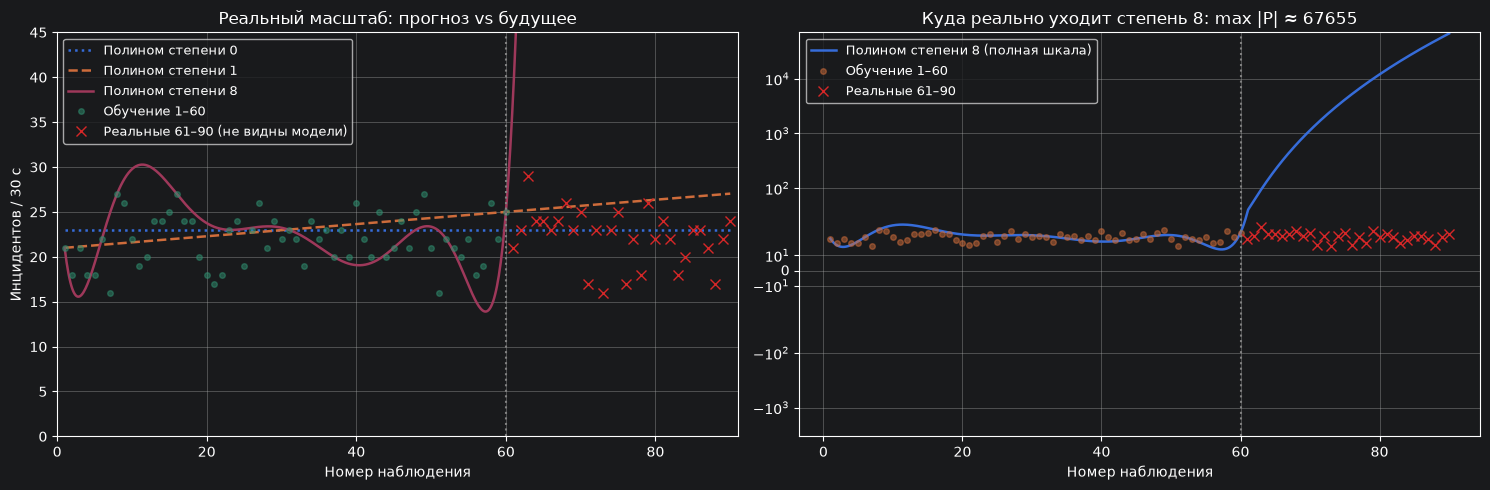

Интерполяция, степень 0: MAE=2.23, MAPE=11.27%
Интерполяция, степень 1: MAE=4.17, MAPE=21.04%
МНК (Чебышёв), степень 3: MAE=5.74, MAPE=28.35%
Интерполяция, степень 8 · Канонический: MAE=14021.43, MAPE=66190.85%
Интерполяция, степень 8 · Лагранж: MAE=14021.43, MAPE=66190.85%
Интерполяция, степень 8 · Ньютон: MAE=14021.43, MAPE=66190.85%
Интерполяция, степень 8 · Эйткен: MAE=14021.43, MAPE=66190.85%

Лучший прогноз на 61–90: Интерполяция, степень 0 (MAE=2.23, MAPE=11.27%).
ВЫВОД: степень, оптимальная по скрытым точкам ВНУТРИ окна 1–60, не гарантирует качества экстраполяции за его пределами.


In [12]:
# Первые 90 значений из total_incidents.csv (файл всего содержит 100 строк; значения вшиты, чтобы Colab-версия оставалась автономной)
Y90 = np.array([
    21,18,21,18,18,22,16,27,26,22,19,20,24,24,25,
    27,24,24,20,18,17,18,23,24,19,23,26,21,24,22,
    23,22,19,24,22,23,20,23,20,26,22,20,25,20,21,
    24,21,25,27,21,16,22,21,20,22,18,19,26,22,25,
    21,23,29,24,24,23,24,26,23,25,17,23,16,23,25,
    17,22,18,26,22,24,22,18,20,23,23,21,17,22,24
], dtype=float)
assert len(Y90) == 90 and np.array_equal(Y90[:60], Y), 'первые 60 значений должны совпадать с исходными данными'
FUT_T, FUT_Y = np.arange(61, 91), Y90[60:]
name_all = 'Все 60 (1–60)'

rows = []
for d in (0, 1):
    p, nx, ny = MODELS[(name_all, d)]
    rows.append({'Модель': f'Интерполяция, степень {d}', **calc_metrics(FUT_Y, evaluate(p, FUT_T, METHODS[0]))})
z = ls_results[ls_results['Интервал'] == name_all].sort_values(['MAE', 'Степень']).iloc[0]
d_ls = int(z['Степень'])
rows.append({'Модель': f'МНК (Чебышёв), степень {d_ls}', **calc_metrics(FUT_Y, ls_models[(name_all, d_ls)](FUT_T.astype(float)))})
for m in METHODS:  # четыре формы одного полинома степени 8 — прогноз должен совпадать
    p, nx, ny = MODELS[(name_all, 8)]
    rows.append({'Модель': f'Интерполяция, степень 8 · {m}', **calc_metrics(FUT_Y, evaluate(p, FUT_T, m))})
fut = pd.DataFrame(rows)
display(fut.round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
dense = np.linspace(1, 90, 700)
for d, st in ((0, ':'), (1, '--'), (8, '-')):
    p, _, _ = MODELS[(name_all, d)]
    ax1.plot(dense, evaluate(p, dense, METHODS[0]), st, lw=1.8, label=f'Полином степени {d}')
ax1.plot(T, Y, 'o', ms=4, alpha=.5, label='Обучение 1–60')
ax1.plot(FUT_T, FUT_Y, 'x', color='tab:red', ms=7, lw=0, label='Реальные 61–90 (не видны модели)')
ax1.axvline(60, color='gray', ls=':'); ax1.set_xlim(0, 91); ax1.set_ylim(0, 45)
ax1.set_title('Реальный масштаб: прогноз vs будущее')
ax1.set_xlabel('Номер наблюдения'); ax1.set_ylabel('Инцидентов / 30 с'); ax1.legend(fontsize=9)
p8, _, _ = MODELS[(name_all, 8)]
hat8 = evaluate(p8, dense, METHODS[0])
ax2.plot(dense, hat8, lw=1.8, label='Полином степени 8 (полная шкала)')
ax2.plot(T, Y, 'o', ms=4, alpha=.5, label='Обучение 1–60')
ax2.plot(FUT_T, FUT_Y, 'x', color='tab:red', ms=7, lw=0, label='Реальные 61–90')
ax2.axvline(60, color='gray', ls=':'); ax2.set_yscale('symlog', linthresh=40)
ax2.set_title(f'Куда реально уходит степень 8: max |P| ≈ {np.max(np.abs(hat8)):.0f}')
ax2.set_xlabel('Номер наблюдения'); ax2.legend(fontsize=9)
plt.tight_layout(); plt.show()

for r in rows:
    print(f'{r["Модель"]}: MAE={r["MAE"]:.2f}, MAPE={r["MAPE"]:.2f}%')
best_fut = fut.sort_values('MAE').iloc[0]
print(f'\nЛучший прогноз на 61–90: {best_fut["Модель"]} (MAE={best_fut["MAE"]:.2f}, MAPE={best_fut["MAPE"]:.2f}%).')
print('ВЫВОД: степень, оптимальная по скрытым точкам ВНУТРИ окна 1–60, не гарантирует качества экстраполяции за его пределами.')

## 11. Полиномы высоких степеней: 29, 47 и 59

**Степень 59** — единственный полином, проходящий сразу через все 60 наблюдений. **Степень 47** — наибольшая, для которой при переборе ещё оставались независимые скрытые точки; **29** — верхняя граница для интервалов из 30 точек. Здесь показано, что происходит при таких степенях:

- на самих узлах полином воспроизводит данные **точно** (для степени 59 — все 60 точек, MAE = 0);
- **между узлами** полиномы степеней 29 и 47 (узлы разрежённые) сильно осциллируют — эффект Рунге, амплитуда до 10⁷–10¹¹; степень 59, у которой узлами служат все 60 точек, между соседними узлами ведёт себя умеренно;
- **экстраполяция** на реальные наблюдения 61–90 даёт астрономические значения у всех трёх — интерполяция и прогноз разные задачи.

Полный набор из 60 коэффициентов степени 59 можно вывести вызовом `show_coeffs('Все 60 (1–60)', degree=59)` из раздела 8.

,Степень,Узлов,MAE на 60 наблюдениях,max |P| внутри окна,max |P| на 61–90,"MAPE на 61–90, %"
0,29,30,3.123004e+05,1.302584e+07,1.241283e+20,4.441314e+19
1,47,48,1.745822e+09,1.044939e+11,9.615048e+31,2.426799e+31
2,59,60,0.000000e+00,2.700000e+01,1.298566e+40,2.840104e+39


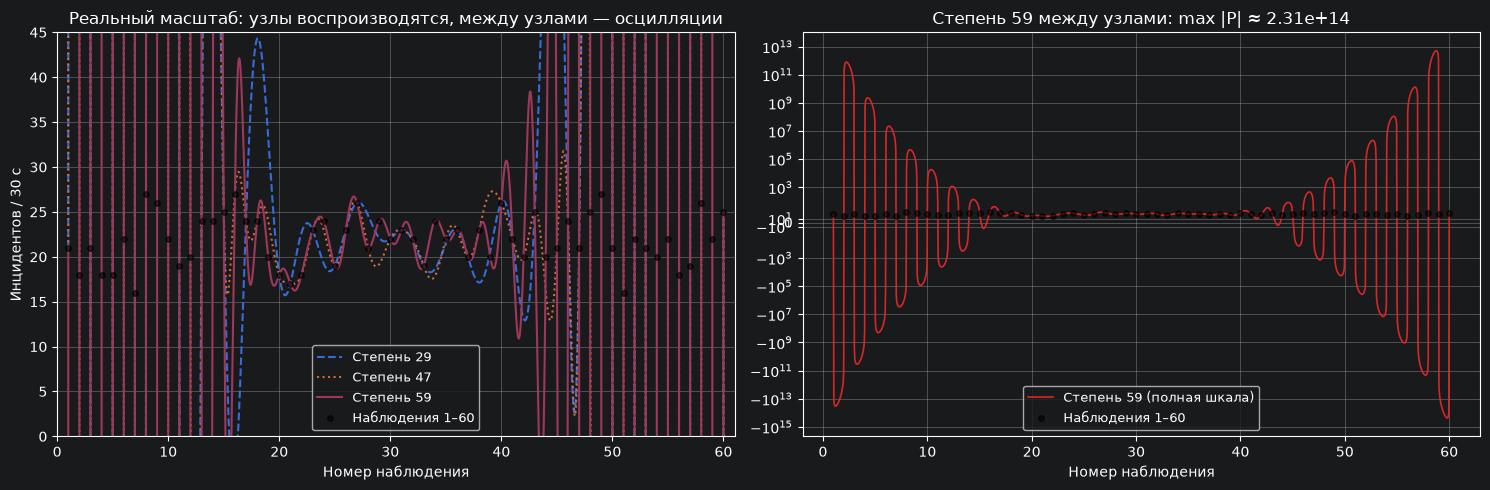

Степень 29: MAE на узлах = 3.12e+05, osc max|P| = 1.30e+07, MAPE прогноз на 61–90 = 4.44e+19%
Степень 47: MAE на узлах = 1.75e+09, osc max|P| = 1.04e+11, MAPE прогноз на 61–90 = 2.43e+31%
Степень 59: MAE на узлах = 0.00e+00, osc max|P| = 2.70e+01, MAPE прогноз на 61–90 = 2.84e+39%

ВЫВОД: степени 29 и 47 осциллируют между разрежёнными узлами до 1e7–1e11; степень 59 точно воспроизводит все 60 точек и умеренно ведёт себя между плотными узлами, но её «прогноз» на 61–90 абсурден — идеальная интерполяция не означает прогноз.


In [13]:
name_all = 'Все 60 (1–60)'
rows = []
for d in (29, 47, 59):
    p, nx, ny = MODELS[(name_all, d)]
    inside = evaluate(p, T, METHODS[0])       # значения на всех 60 наблюдениях
    future = evaluate(p, FUT_T, METHODS[0])   # прогноз на реальные 61–90
    rows.append({'Степень': d, 'Узлов': d + 1,
                 'MAE на 60 наблюдениях': calc_metrics(Y, inside)['MAE'],
                 'max |P| внутри окна': float(np.max(np.abs(inside))),
                 'max |P| на 61–90': float(np.max(np.abs(future))),
                 'MAPE на 61–90, %': calc_metrics(FUT_Y, future)['MAPE']})
hi = pd.DataFrame(rows)
display(hi)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
dense = np.linspace(1, 60, 1500)
for d, st in ((29, '--'), (47, ':'), (59, '-')):
    p, _, _ = MODELS[(name_all, d)]
    ax1.plot(dense, evaluate(p, dense, METHODS[0]), st, lw=1.5, label=f'Степень {d}')
ax1.plot(T, Y, 'o', ms=4, color='black', alpha=.6, label='Наблюдения 1–60')
ax1.set_ylim(0, 45); ax1.set_xlim(0, 61)
ax1.set_title('Реальный масштаб: узлы воспроизводятся, между узлами — осцилляции')
ax1.set_xlabel('Номер наблюдения'); ax1.set_ylabel('Инцидентов / 30 с'); ax1.legend(fontsize=9)
p59 = MODELS[(name_all, 59)][0]
hat59 = evaluate(p59, dense, METHODS[0])
ax2.plot(dense, hat59, lw=1.2, color='tab:red', label='Степень 59 (полная шкала)')
ax2.plot(T, Y, 'o', ms=4, color='black', alpha=.6, label='Наблюдения 1–60')
ax2.set_yscale('symlog', linthresh=40)
ax2.set_title(f'Степень 59 между узлами: max |P| ≈ {np.max(np.abs(hat59)):.2e}')
ax2.set_xlabel('Номер наблюдения'); ax2.legend(fontsize=9)
plt.tight_layout(); plt.show()

for r in rows:
    print(f'Степень {int(r["Степень"])}: MAE на узлах = {r["MAE на 60 наблюдениях"]:.2e}, '
          f'osc max|P| = {r["max |P| внутри окна"]:.2e}, MAPE прогноз на 61–90 = {r["MAPE на 61–90, %"]:.2e}%')
print('\nВЫВОД: степени 29 и 47 осциллируют между разрежёнными узлами до 1e7–1e11; '
      'степень 59 точно воспроизводит все 60 точек и умеренно ведёт себя между плотными узлами, '
      'но её «прогноз» на 61–90 абсурден — идеальная интерполяция не означает прогноз.')

## 11.1. Полином степени 36: подробный разбор

Степень 36 — середина диапазона 35–37: узлы ещё разрежённые (37 из 48 обучающих точек), а 12 скрытых наблюдений остаются независимыми для проверки. Ниже — сводка по этому полиному: точность на узлах, скрытых точках, всех 60 наблюдениях и на реальном будущем 61–90; согласие четырёх вычислительных форм; амплитуда осцилляций между узлами. Левый график — реальный масштаб (полином проходит через узлы, но промахивается по скрытым точкам), правый — полная шкала symlog, включая окно прогноза 61–90.

,Ряд,MAE,MSE,RMSE,MAPE
0,Узлы (37 обучающих точек),0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1,"Скрытые точки (12, независимые)",1.323664e+07,1.972832e+15,4.441657e+07,6.058971e+07
2,Все 60 наблюдений,3.178454e+06,4.084506e+14,2.021016e+07,1.467313e+07
3,Реальное будущее 61–90,1.811812e+23,3.290243e+47,5.736064e+23,8.221154e+23


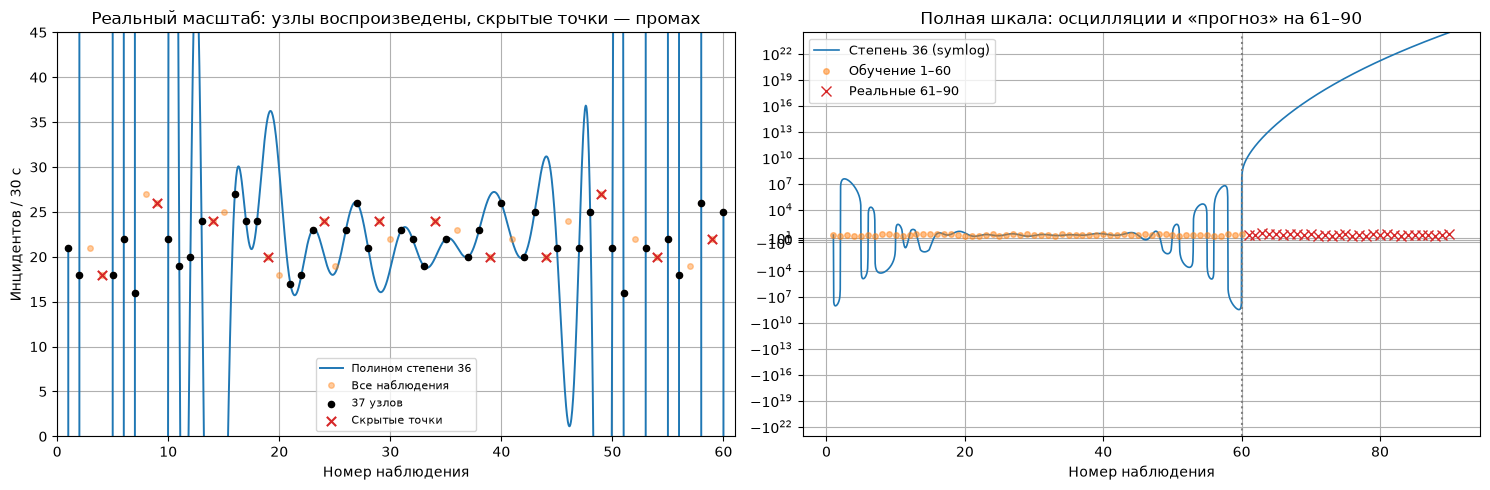

ОТЧЁТ по полиному степени 36 (интервал Все 60 (1–60)):
  узлов: 37 из 48 обучающих точек; скрытых (независимых): 12
  MAE на узлах: 0.00e+00 (интерполяция точная)
  MAE на скрытых: 1.324e+07;  MAPE: 6.059e+07%
  max |P| внутри окна 1–60: 3.225e+08
  расхождение четырёх форм на пробных точках 1..90: 0.00e+00
  прогноз на 61–90: max |P| = 2.709e+24;  MAE = 1.812e+23;  MAPE = 8.221e+23%


In [14]:
D, name_all = 36, 'Все 60 (1–60)'
p, nx, ny = MODELS[(name_all, D)]
sx, sy = SCAN[name_all]['test_x'], SCAN[name_all]['test_y']

rep = pd.DataFrame([
    {'Ряд': f'Узлы ({D+1} обучающих точек)',   **calc_metrics(ny, evaluate(p, nx, METHODS[0]))},
    {'Ряд': f'Скрытые точки ({len(sx)}, независимые)', **calc_metrics(sy, evaluate(p, sx, METHODS[0]))},
    {'Ряд': 'Все 60 наблюдений',               **calc_metrics(Y,  evaluate(p, T,  METHODS[0]))},
    {'Ряд': 'Реальное будущее 61–90',          **calc_metrics(FUT_Y, evaluate(p, FUT_T, METHODS[0]))},
])
display(rep.round(3))

dense = np.linspace(1, 60, 1500)
in_hat = evaluate(p, dense, METHODS[0])
fut_hat = evaluate(p, FUT_T, METHODS[0])

probes = list(range(1, 91, 3))
vals = {m: evaluate(p, probes, m) for m in METHODS}
maxdiff = max(float(np.max(np.abs(vals[a] - vals[b]))) for a in METHODS for b in METHODS)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.plot(dense, in_hat, lw=1.4, label=f'Полином степени {D}')
ax1.plot(T, Y, 'o', ms=4, alpha=.4, label='Все наблюдения')
ax1.scatter(nx, ny, s=20, color='black', zorder=4, label=f'{D+1} узлов')
ax1.scatter(sx, sy, marker='x', s=45, color='tab:red', zorder=4, label='Скрытые точки')
ax1.set_ylim(0, 45); ax1.set_xlim(0, 61)
ax1.set_title('Реальный масштаб: узлы воспроизведены, скрытые точки — промах')
ax1.set_xlabel('Номер наблюдения'); ax1.set_ylabel('Инцидентов / 30 с'); ax1.legend(fontsize=8)
dense90 = np.linspace(1, 90, 1800)
ax2.plot(dense90, evaluate(p, dense90, METHODS[0]), lw=1.2, label=f'Степень {D} (symlog)')
ax2.plot(T, Y, 'o', ms=4, alpha=.5, label='Обучение 1–60')
ax2.plot(FUT_T, FUT_Y, 'x', color='tab:red', ms=7, lw=0, label='Реальные 61–90')
ax2.axvline(60, color='gray', ls=':')
ax2.set_yscale('symlog', linthresh=40)
ax2.set_title('Полная шкала: осцилляции и «прогноз» на 61–90')
ax2.set_xlabel('Номер наблюдения'); ax2.legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f'ОТЧЁТ по полиному степени {D} (интервал {name_all}):')
print(f'  узлов: {D+1} из {len(SCAN[name_all]["train_x"])} обучающих точек; скрытых (независимых): {len(sx)}')
print(f'  MAE на узлах: {calc_metrics(ny, evaluate(p, nx, METHODS[0]))["MAE"]:.2e} (интерполяция точная)')
print(f'  MAE на скрытых: {calc_metrics(sy, evaluate(p, sx, METHODS[0]))["MAE"]:.3e};  MAPE: {calc_metrics(sy, evaluate(p, sx, METHODS[0]))["MAPE"]:.3e}%')
print(f'  max |P| внутри окна 1–60: {np.max(np.abs(in_hat)):.3e}')
print(f'  расхождение четырёх форм на пробных точках 1..90: {maxdiff:.2e}')
print(f'  прогноз на 61–90: max |P| = {np.max(np.abs(fut_hat)):.3e};  MAE = {calc_metrics(FUT_Y, fut_hat)["MAE"]:.3e};  MAPE = {calc_metrics(FUT_Y, fut_hat)["MAPE"]:.3e}%')

## 12. Как всё-таки прогнозировать: короткий прогноз на 3 шага вперёд

Разделы 10–11 показали: глобальные интерполяционные полиномы (степени 8 и выше) для прогноза непригодны — ошибка растёт до 10²⁰–10³⁹ %. **Рабочая схема для шумных данных — простые локальные модели по свежим наблюдениям и короткий горизонт:**

1. берём последние `K = 6` наблюдений (окно);
2. строим простую модель: константа / линейная / квадратичная (МНК по окну);
3. продлеваем её на `H = 3` шага вперёд (t = 61, 62, 63);
4. как только приходит фактическое значение — сдвигаем окно и считаем заново («идущий» прогноз).

Фактические значения 61–63 известны из `total_incidents.csv` и используются **только для проверки** — модели видят лишь наблюдения 1–60.

,Модель,t=61,t=62,t=63,"MAPE 3 точки, %"
0,**ФАКТ (61–63)**,21.0,23.00,29.00,0.00
1,Наивная (последнее значение),25.0,25.00,25.00,13.85
2,"Среднее последних 6 (степень 0, МНК)",22.0,22.00,22.00,11.08
3,"Линейная (степень 1, МНК по последним 6)",25.4,26.37,27.34,13.78
4,"Квадратичная (степень 2, МНК по последним 6)",27.9,31.01,34.66,29.08
5,«Идущий» линейный (пересчёт по факту),25.4,24.73,23.47,15.86


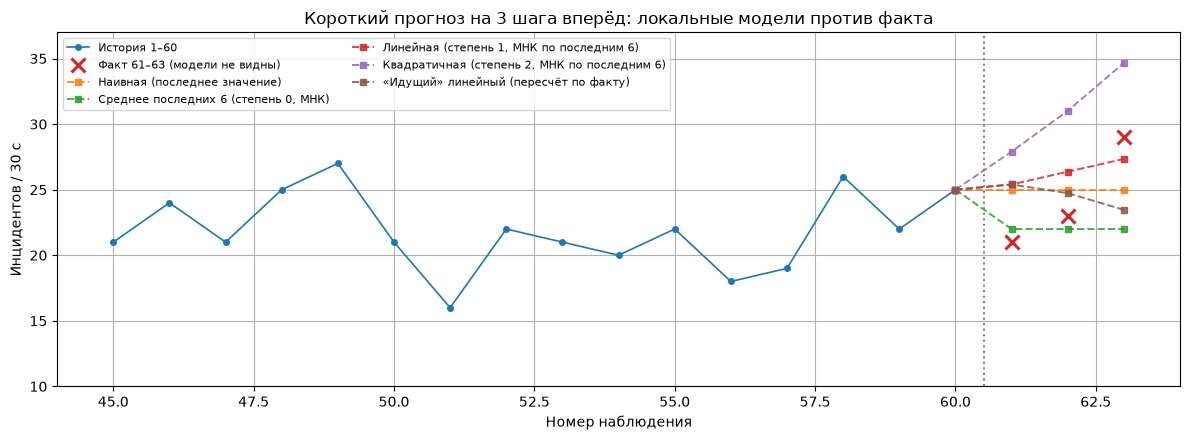

Наивная (последнее значение): прогноз [25.0, 25.0, 25.0] → MAE=3.33, MAPE=13.85%
Среднее последних 6 (степень 0, МНК): прогноз [22.0, 22.0, 22.0] → MAE=3.00, MAPE=11.08%
Линейная (степень 1, МНК по последним 6): прогноз [25.4, 26.37, 27.34] → MAE=3.14, MAPE=13.78%
Квадратичная (степень 2, МНК по последним 6): прогноз [27.9, 31.01, 34.66] → MAE=6.86, MAPE=29.08%
«Идущий» линейный (пересчёт по факту): прогноз [25.4, 24.73, 23.47] → MAE=3.89, MAPE=15.86%

ФАКТ 61–63: [21, 23, 29]
ЛУЧШАЯ МОДЕЛЬ: Среднее последних 6 (степень 0, МНК) (MAPE=11.08%)
ВЫВОД: прогнозировать позволяют только простые локальные модели на коротком горизонте; 
интерполяционный полином высокой степени остаётся инструментом описания истории, а не прогноза.


In [15]:
K, H = 6, 3                      # окно из последних наблюдений и горизонт прогноза
TFT, ACT = FUT_T[:H], FUT_Y[:H]  # t = 61,62,63 и фактические значения (только для проверки)

def fit_last(deg, t_hist=None, y_hist=None):
    tt = np.asarray((t_hist if t_hist is not None else T)[-K:], float)
    yy = np.asarray((y_hist if y_hist is not None else Y)[-K:], float)
    return np.polyfit(tt, yy, deg)

models = {}
models['Наивная (последнее значение)'] = np.full(H, Y[-1])
models[f'Среднее последних {K} (степень 0, МНК)'] = np.polyval(fit_last(0), TFT)
models[f'Линейная (степень 1, МНК по последним {K})'] = np.polyval(fit_last(1), TFT)
models[f'Квадратичная (степень 2, МНК по последним {K})'] = np.polyval(fit_last(2), TFT)
t_hist, y_hist, roll = list(T), list(Y), []
for i in range(H):  # «идущий» прогноз: пересчёт по мере поступления факта
    c = np.polyfit(np.array(t_hist[-K:], float), np.array(y_hist[-K:], float), 1)
    roll.append(float(np.polyval(c, t_hist[-1] + 1)))
    t_hist.append(int(TFT[i])); y_hist.append(float(ACT[i]))
models['«Идущий» линейный (пересчёт по факту)'] = np.array(roll)

rows = [{'Модель': '**ФАКТ (61–63)**', **{f't={int(TFT[i])}': int(ACT[i]) for i in range(H)}, 'MAPE 3 точки, %': 0.0}]
for n, v in models.items():
    rows.append({'Модель': n, **{f't={int(TFT[i])}': round(float(v[i]), 2) for i in range(H)},
                 'MAPE 3 точки, %': round(calc_metrics(ACT, v)['MAPE'], 2)})
pred_tbl = pd.DataFrame(rows)
display(pred_tbl)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(T[44:], Y[44:], 'o-', ms=4, lw=1.2, label='История 1–60')
ax.plot(TFT, ACT, 'x', color='tab:red', ms=10, mew=2.2, label='Факт 61–63 (модели не видны)')
for n, v in models.items():
    ax.plot(np.r_[T[-1], TFT], np.r_[Y[-1], v], '--s', ms=5, lw=1.4, alpha=.85, label=n)
ax.axvline(60.5, color='gray', ls=':')
ax.set_xlim(44, 64); ax.set_ylim(10, 37)
ax.set_title('Короткий прогноз на 3 шага вперёд: локальные модели против факта')
ax.set_xlabel('Номер наблюдения'); ax.set_ylabel('Инцидентов / 30 с')
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

best = min(models.items(), key=lambda kv: calc_metrics(ACT, kv[1])['MAPE'])
for n, v in models.items():
    m = calc_metrics(ACT, v)
    print(f'{n}: прогноз {np.round(v, 2).tolist()} → MAE={m["MAE"]:.2f}, MAPE={m["MAPE"]:.2f}%')
print(f'\nФАКТ 61–63: {ACT.astype(int).tolist()}')
print(f'ЛУЧШАЯ МОДЕЛЬ: {best[0]} (MAPE={calc_metrics(ACT, best[1])["MAPE"]:.2f}%)')
print('ВЫВОД: прогнозировать позволяют только простые локальные модели на коротком горизонте; ')
print('интерполяционный полином высокой степени остаётся инструментом описания истории, а не прогноза.')

## 13. Итоговые рекомендации для отчёта

1. По **60 точкам** возможен однозначный интерполяционный полином степени **59**, но не уникальный полином степени 60.
2. Все четыре метода получаются математически эквивалентными — выбор формы вычисления не заменяет выбор степени и узлов.
3. **Точная подгонка узлов не означает качественного прогноза**: высокие степени способны сильно осциллировать между ними (эффект Рунге и переобучение).
4. Обоснованная степень определяется по ошибкам на **скрытых точках**, не использованных при построении. На двух временных интервалах результаты могут отличаться.
5. В разделе с графиками и таблицами можно показать полиномы **высокой, средней и выбранной степени**, а в приложении сослаться на полный автоматизированный перебор всех степеней.

6. Проверка на реальных будущих наблюдениях 61–90 (из `total_incidents.csv`, всего 100 строк): полином степени 8 — MAPE ≈ 66191%, степени 0 и 1 — ≈ 11% и 21%, МНК — ≈ 28%. Формально «оптимальная» интерполяционная степень при выходе за окно наблюдений сразу теряет качество; простые полиномы малой степени и сглаживание МНК прогнозируют шумные данные не хуже.

7. Полиномы степеней 29 и 47 с разрежёнными узлами осциллируют между узлами до 10⁷–10¹¹ (эффект Рунге). Степень 59 проходит через все 60 точек (MAE на узлах = 0) и умеренно ведёт себя между плотными узлами, но её «прогноз» на 61–90 даёт MAPE ≈ 2.8e+39%: идеальная интерполяция не имеет отношения к прогнозу будущих значений.

8. Рабочая схема краткосрочного прогноза — простые локальные модели по последним наблюдениям: на горизонте 3 шага (t = 61–63, факт 21–29) лучшей оказалась «Среднее последних 6 (степень 0, МНК)» (MAPE ≈ 11%). Высокие интерполяционные степени описывают историю, но не прогнозируют будущее.

**Важно:** прогнозирование следующих, будущих временных интервалов — это *экстраполяция*, и она может оказаться существенно хуже даже при хорошей интерполяции внутри наблюдаемого диапазона.